# Breaking an O–H Bond

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/11-bond-dissociation.ipynb)
:::


In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
_ = psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.



  Memory set to   1.863 GiB by Python driver.


What happens when we pull one hydrogen away from water? The products are two **radicals**, $\mathrm{H_2O \rightarrow HO^\bullet + H^\bullet}$. Describing this correctly is harder than it looks, and it teaches one of the most important lessons in computational chemistry: **a calculation can finish without errors and still be physically wrong.**

## What You Will Learn
- Why **restricted** Hartree–Fock (RHF) fails when a bond breaks, and how **unrestricted** HF (UHF) fixes it.
- How to use `guess_mix` and `stability_analysis` to find the right UHF solution.
- How electron correlation (CCSD(T)) changes the curve.
- How to fit the curve to the **Morse** and **harmonic** potentials and estimate the bond dissociation energy.

Experiment: $D_0(\mathrm{HO{-}H}) = 492$ kJ/mol at 0 K (Ruscic *et al.*, *J. Phys. Chem. A* **2002**, *106*, 2727). Adding back the difference in zero-point energy between H₂O and OH (about 33 kJ/mol) gives a well depth of $D_e \approx 526$ kJ/mol.

In [2]:
psi4.set_output_file("output/11-bond-dissociation.out", False);
h2kJ = psi4.constants.hartree2kJmol

## 1. The Problem with RHF

In RHF each orbital holds two electrons with **the same spatial shape**, one spin up and one spin down. That works well for a normal bond. When the bond breaks, one electron should end up on O and the other on H, but RHF still forces them into the same orbital. The result is a mixture of the radical products with ions ($\mathrm{HO^- + H^+}$ and $\mathrm{HO^+ + H^-}$), which are far higher in energy.

UHF lets the spin-up and spin-down electrons have **different** orbitals, so they can separate onto the two fragments. However, near the equilibrium structure the best UHF solution is identical to RHF, so we have to **push** the calculation towards the broken-symmetry solution.

```{note} Psi4 settings for bond breaking
:class: dropdown
`reference: "uhf"`
: Unrestricted Hartree–Fock. *Alternatives:* `"rhf"` (closed shell; fails here), `"rohf"` (restricted open-shell, used for radicals but cannot describe a singlet breaking into two doublets), `"uks"` for unrestricted DFT.

`guess_mix: True`
: Mixes the HOMO and LUMO in the starting guess so that the spin-up and spin-down orbitals start out different. It only works in $C_1$ symmetry, so we add `symmetry c1` to the geometry. On its own it is often **not enough**: the SCF can slide back to the RHF-like solution.

`stability_analysis: "follow"`
: After the SCF converges, *Psi4* checks whether a lower-energy UHF solution exists nearby. If it finds one, it follows it downhill and re-converges. Together with `guess_mix`, this reliably finds the broken-symmetry solution. *Alternative:* `"check"` reports instabilities without following them.

`scf__maxiter: 200`
: Stretched bonds converge slowly; we allow more SCF iterations than the default 100. The `scf__` prefix applies the option to the SCF module only, so the coupled-cluster code keeps its own limit.

`scf_type: "pk"` and `freeze_core: True`
: Exact integrals (needed for the conventional CCSD(T) code) and an uncorrelated O 1s core.
```

## 2. The Products on Their Own

First we find the true dissociation limit by calculating OH and H separately, each a **doublet** (one unpaired electron, multiplicity 2). The OH bond length is fixed at the same 0.958 Å used in the scan so that the curve and the limit match. A hydrogen atom has only one electron, so there is no electron correlation to calculate: its UHF energy is already exact for this basis set, and we use it for every method.

In [3]:
common = {"basis": "cc-pvtz", "scf_type": "pk", "freeze_core": True, "scf__maxiter": 200}

psi4.set_options({**common, "reference": "uhf"})
OH = psi4.geometry("""
0 2
O
H 1 0.958
""")
H = psi4.geometry("""
0 2
H
""")

E_H = psi4.energy("scf", molecule=H)     # one electron: no correlation, so CCSD(T) = UHF exactly

limit = {}
limit["CCSD(T)"] = psi4.energy("ccsd(t)", molecule=OH) + E_H
limit["UHF"] = psi4.energy("scf", molecule=OH) + E_H
psi4.core.clean_options()
psi4.core.clean()                 # delete the coupled-cluster scratch files before the next molecule

for method, E in limit.items():
    print(f"{method:8s} E(OH) + E(H) = {E:.6f} hartree")

CCSD(T)  E(OH) + E(H) = -76.137375 hartree
UHF      E(OH) + E(H) = -75.919368 hartree


## 3. The Scan

We stretch one O–H bond and keep the other bond (0.958 Å) and the angle (104.5°) fixed. This is a **rigid scan**; a relaxed scan would also let the other bond and angle adjust (see the *Bending Scan* notebook for how to freeze a coordinate).

We calculate three curves with the cc-pVTZ basis set: RHF, UHF and CCSD(T) built on UHF. The full scan takes a few minutes (about 3–5 on *Colab*). If a calculation fails to converge, we record `NaN` (not a number) and carry on; failures are themselves information.

In [4]:
distances = np.array([0.70, 0.80, 0.85, 0.90, 0.95, 1.00, 1.05, 1.10, 1.20, 1.30, 1.40,
                      1.50, 1.75, 2.00, 2.25, 2.50, 3.00, 3.50, 4.00, 5.00])

def stretched(r):
    return psi4.geometry(f"""
    0 1
    O
    H 1 0.958
    H 1 {r} 2 104.5
    symmetry c1
    """)

uhf_options = {"reference": "uhf", "guess_mix": True, "stability_analysis": "follow"}

rows = []
for r in distances:
    row = {"r": r}

    psi4.core.clean_options()
    psi4.set_options({**common, "reference": "rhf"})
    try:
        row["RHF"] = psi4.energy("scf", molecule=stretched(r))
    except psi4.SCFConvergenceError:
        row["RHF"] = np.nan                   # RHF sometimes cannot even converge far out
        psi4.core.clean()

    psi4.core.clean_options()
    psi4.set_options({**common, **uhf_options})
    try:
        row["UHF"] = psi4.energy("scf", molecule=stretched(r))
        if r <= 3.5:                            # see the note below about longer distances
            row["CCSD(T)"] = psi4.energy("ccsd(t)", molecule=stretched(r))
        else:
            row["CCSD(T)"] = np.nan
    except Exception:                          # SCF or coupled-cluster equations failed to converge
        row.setdefault("UHF", np.nan)
        row["CCSD(T)"] = np.nan
    psi4.core.clean()                          # remove scratch files before the next point
    rows.append(row)

psi4.core.clean_options()
curve = pd.DataFrame(rows)
curve.round(6)

,r,RHF,UHF,CCSD(T)
0,0.70,-75.937692,-75.937692,-76.204263
1,0.80,-76.026089,-76.026089,-76.295694
2,0.85,-76.045876,-76.045876,-76.317135
3,0.90,-76.055314,-76.055314,-76.328303
4,0.95,-76.057328,-76.057328,-76.332116
5,1.00,-76.054043,-76.054043,-76.330693
6,1.05,-76.047012,-76.047012,-76.325584
7,1.10,-76.037371,-76.037371,-76.317929
8,1.20,-76.013404,-76.013404,-76.298144
9,1.30,-75.986556,-75.986556,-76.275842


```{note} Why no CCSD(T) beyond 3.5 Å?
:class: dropdown
If you remove the `if r <= 3.5` test, the coupled-cluster equations fail to converge at 4 and 5 Å. Far apart, the two $\pi$ orbitals of the OH radical become almost equal in energy, and a single-reference method like CCSD(T) struggles to decide which one holds the unpaired electron. Calculating the fragments separately (section 2) gives the dissociation limit anyway. The coupled-cluster code also leaves scratch files behind that can break the next calculation on a **different** molecule (with a confusing `PSIO_ERROR`). That is why we call `psi4.core.clean()` after every coupled-cluster calculation.
```

Now we can measure the well depth $D_e$ for each method: the energy of the separated products minus the lowest point of the curve.

In [5]:
for method in ["UHF", "CCSD(T)"]:
    De = (limit[method] - curve[method].min()) * h2kJ
    print(f"{method:8s} De = {De:6.1f} kJ/mol")
print("experiment De ≈ 526 kJ/mol")

last = curve["RHF"].last_valid_index()
print(f"\nRHF never levels off: at {curve['r'][last]} Å it is already "
      f"{(curve['RHF'][last] - curve['RHF'].min()) * h2kJ:.0f} kJ/mol above its minimum.")

UHF      De =  362.2 kJ/mol
CCSD(T)  De =  511.3 kJ/mol
experiment De ≈ 526 kJ/mol

RHF never levels off: at 3.5 Å it is already 993 kJ/mol above its minimum.


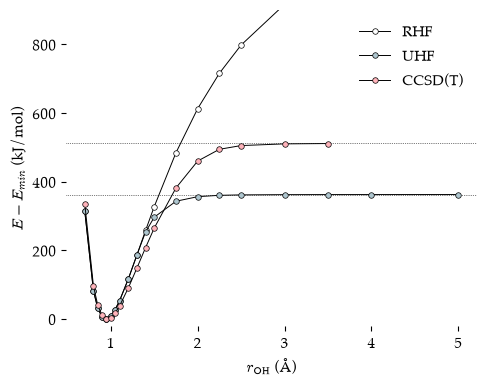

In [6]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
colors = {"RHF": "white", "UHF": "#AEC6CF", "CCSD(T)": "#FFB3BA"}
for method, color in colors.items():
    E = (curve[method] - curve[method].min()) * h2kJ
    ax.plot(curve["r"], E, color="black", linewidth=0.7, marker="o", markersize=4,
            markerfacecolor=color, markeredgecolor="black", markeredgewidth=0.5, label=method)
for method in ["UHF", "CCSD(T)"]:     # dotted lines: the OH + H limit for each method
    ax.axhline((limit[method] - curve[method].min()) * h2kJ, color="black", linewidth=0.5, linestyle=":", zorder=1)
ax.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax.set_ylabel(r"$E - E_{min}$ (kJ/mol)")
ax.set_ylim(-20, 900)
ax.legend()
plt.show()

What the curves show (the dotted lines mark the OH + H limit for UHF and CCSD(T)):

- **RHF** rises far too high and never levels off at the radical limit. Every calculation "worked", but the answer is wrong.
- **UHF** follows RHF near the minimum, then splits away and levels off correctly at OH + H. The point where it splits is where the RHF solution becomes **unstable**. But UHF badly **underestimates** $D_e$ because it lacks electron correlation, which is worth more in the intact molecule than in the separated radicals.
- **CCSD(T)** gives a well depth close to experiment. Look at the table: RHF could not even converge at the longest distances (`NaN`).

## 4. Morse or Harmonic?

The *Vibrations* notebook used the **harmonic** approximation, $V = \tfrac{1}{2}k(r - r_e)^2$. The **Morse** potential is a better model of a real bond because it levels off at the dissociation energy:

$$
V(r) = D_e\left[1 - e^{-a(r - r_e)}\right]^2
$$

We fit the Morse function to the CCSD(T) curve, then draw the harmonic potential with the same curvature at the minimum ($k = 2D_e a^2$).

Morse fit: De = 532 kJ/mol, a = 2.28 Å^-1, re = 0.957 Å


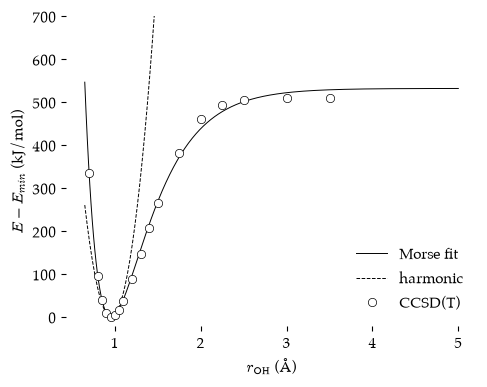

In [7]:
from scipy.optimize import curve_fit

def morse(r, De, a, re):
    return De * (1 - np.exp(-a * (r - re)))**2

ok = curve["CCSD(T)"].notna()
r = curve.loc[ok, "r"].to_numpy()
E = ((curve.loc[ok, "CCSD(T)"] - curve["CCSD(T)"].min()) * h2kJ).to_numpy()
params, _ = curve_fit(morse, r, E, p0=[500, 2.0, 0.96])
De_fit, a_fit, re_fit = params
k = 2 * De_fit * a_fit**2           # kJ/mol per Å^2

print(f"Morse fit: De = {De_fit:.0f} kJ/mol, a = {a_fit:.2f} Å^-1, re = {re_fit:.3f} Å")

r_fine = np.linspace(0.65, 5.0, 300)
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(r_fine, morse(r_fine, *params), color="black", linewidth=0.7, zorder=1, label="Morse fit")
ax.plot(r_fine, 0.5 * k * (r_fine - re_fit)**2, color="black", linewidth=0.7, linestyle="--", zorder=1, label="harmonic")
ax.plot(r, E, linestyle="none", marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2, label="CCSD(T)")
ax.set_ylim(-20, 700)
ax.set_xlabel(r"$r_{\mathrm{OH}}$ (Å)")
ax.set_ylabel(r"$E - E_{min}$ (kJ/mol)")
ax.legend()
plt.show()

Near the bottom the two potentials agree, which is why the harmonic approximation works for vibrational frequencies. Higher up, the harmonic potential rises forever while the real bond softens and breaks. This **anharmonicity** is why observed vibrational frequencies are lower than harmonic ones.

The fit is not perfect: the other O–H bond and the angle are frozen, and a single Morse function cannot match the whole curve exactly. For accurate work at stretched geometries, **multireference** methods (such as CASSCF and MRCI) are used; they are designed for exactly this kind of near-degeneracy.

```{tip} From $D_e$ to $D_0$
The bond dissociation energy measured in experiments is $D_0 = D_e - \Delta \mathrm{ZPE}$, where $\Delta \mathrm{ZPE} = \mathrm{ZPE(H_2O)} - \mathrm{ZPE(OH)}$. Use the *Thermochemistry* notebook to calculate both zero-point energies and turn the CCSD(T) $D_e$ into a $D_0$ to compare with 492 kJ/mol.
```

## Summary
- RHF cannot describe homolytic bond breaking; use UHF (with `guess_mix` and `stability_analysis: "follow"`).
- Electron correlation is essential for a good dissociation energy.
- The Morse potential captures the anharmonic shape of a real bond; the harmonic potential only works near the minimum.